# Data Exploration

Here are some basic steps we can take when confronted with a dataset. We don't always go through all of these in order, but if we spend enough time with a dataset, we usually end up returning to all of these, often more than once.

1. Get oriented: shape (how many rows/columns/participants/etc.), dtypes, missing values, descriptive statistics.
2. Look at each variable: distributions, outliers, categorical breakdowns.
3. Investigate relationships: correlations, groupings, counts.
4. Transform & re-visualize: encode, aggregate, drop, pivot; look again.
5. Form mini hypotheses and questions: "Why is the data in column X skewed?" / "Why might columns Y and Z be correlated?"
6. Repeat as you refine your questions.

## Adult Language Learning Profile

These data come from a (surprise!) Dutch study (Schepens et al, 2020), that collected scores by adult language learners on a test of spoken Dutch ("STEX"). 

They also collected data on the learners such as their education level, their native language, their country of birth, length of time in the Netherlands, and the similarity of their native language to Dutch, etc. Below you can see all the types of data they collected, together with the abbreviations in the column headers.


The columns of data are:  

- "L1" - The first language of the learner
- "C" - The country of birth
- "L1L2" - The combination of first and best additional language besides Dutch
- "L2" - The best additional language besides Dutch
- "AaA" - Age at Arrival in the Netherlands in years (starting date of residence)
- "LoR" - Length of residence in the Netherlands in years
- "Edu.day" - Duration of daily education (1 low, 2 middle, 3 high, 4 very high). From 1992 until 2006, learners' education has been measured by means of a side-by-side matrix question in a learner's questionnaire. Learners were asked to mark which type of education they have had (elementary, secondary, or tertiary schooling) by means of filling in for how many years they have been enrolled, in which country, and whether or not they have graduated. Based on this information we were able to estimate how many years learners have had education on a daily basis from six years of age onwards. Since 2006, the question about learners' education has been altered and it is asked directly how many years learners have had formal education on a daily basis from six years of age onwards. Possible answering categories are: 1) 0 thru 5 years; 2) 6 thru 10 years; 3) 11 thru 15 years; 4) 16 years or more. The answers have been merged into the categorical answer.
- "Sex" - Gender
- "Family" - Language Family
- "ISO639.3" - Language ID code according to Ethnologue
- "Enroll" - Proportion of school-aged youth enrolled in secondary education according to the World Bank. The World Bank reports on education data in a wide number of countries around the world on a regular basis. We took the gross enrollment rate in secondary schooling per country in the year the learner has arrived in the Netherlands as an indicator for a country's educational accessibility at the time learners have left their country of origin.
- "STEX_speaking_score" - The STEX test score for speaking proficiency.
- "Dissimilarity_morphological" - Morphological similarity
- "Dissimilarity_lexical" - Lexical similarity
- "Dissimilarity_phonological_new_features" - Phonological similarity (in terms of new features)
- "Dissimilarity_phonological_new_categories" - Phonological similarity (in terms of new sounds)


There are rich opportunities here for investigation. Work your way through some of the steps of data exploration listed above (orientation, investigation, visualization, etc.), and see what you can find.

### References
Schepens, Job, Roeland van Hout, and T. Florian Jaeger. “Big Data Suggest Strong Constraints of Linguistic Similarity on Adult Language Learning.” Cognition 194 (January 1, 2020): 104056. https://doi.org/10.1016/j.cognition.2019.104056. https://zenodo.org/records/2863533#.Y9Y3pNJBwUE

In [2]:
import pandas as pd
import seaborn as sns
import pingouin as pg

url = 'https://raw.githubusercontent.com/ethanweed/ExPsyLing/master/notebooks/data%20exploration/stex.csv'
df = pd.read_csv(url, encoding="cp1252")

In [63]:
corr_matrix = df.corr(numeric_only=True)

In [64]:
corr_matrix

,AaA,LoR,Edu.day,Enroll,Speaking,morph,lex,new_feat,new_sounds,L1_Order,Sex_numeric
AaA,1.000000,-0.188312,0.219943,-0.003540,-0.136891,0.000449,-0.037035,0.059373,0.041512,-0.011546,-0.004898
LoR,-0.188312,1.000000,-0.091627,-0.082751,0.006867,0.076976,0.098486,0.042704,0.055825,0.015293,-0.055419
Edu.day,0.219943,-0.091627,1.000000,0.027248,0.034630,-0.003215,-0.013897,0.026316,0.031624,-0.006202,0.040882
Enroll,-0.003540,-0.082751,0.027248,1.000000,0.372622,-0.335544,-0.512117,-0.462783,-0.326703,0.061202,0.316729
Speaking,-0.136891,0.006867,0.034630,0.372622,1.000000,-0.323426,-0.437331,-0.325470,-0.326212,-0.084073,0.228946
morph,0.000449,0.076976,-0.003215,-0.335544,-0.323426,1.000000,0.599171,0.504820,0.396680,0.060170,-0.034699
lex,-0.037035,0.098486,-0.013897,-0.512117,-0.437331,0.599171,1.000000,0.628929,0.581581,0.148665,-0.202279
new_feat,0.059373,0.042704,0.026316,-0.462783,-0.325470,0.504820,0.628929,1.000000,0.665045,-0.053627,-0.155138
new_sounds,0.041512,0.055825,0.031624,-0.326703,-0.326212,0.396680,0.581581,0.665045,1.000000,0.154605,-0.139360
L1_Order,-0.011546,0.015293,-0.006202,0.061202,-0.084073,0.060170,0.148665,-0.053627,0.154605,1.000000,0.075470


In [61]:
df.head()

,L1,C,L1L2,L2,AaA,LoR,Edu.day,Sex,Family,ISO639.3,Enroll,Speaking,morph,lex,new_feat,new_sounds,L1_Order,Sex_numeric
0,Afrikaans,SouthAfrica,AfrikaansEnglish,English,25,0,4.0,Female,Indo-European,afr,93,496,NaN,0.010463,NaN,NaN,0,1
1,Afrikaans,SouthAfrica,AfrikaansGerman,German,47,2,4.0,Male,Indo-European,afr,93,542,NaN,0.010463,NaN,NaN,0,0
2,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,23,23,3.0,Female,Indo-European,afr,93,585,NaN,0.010463,NaN,NaN,0,1
3,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,42,2,2.0,Female,Indo-European,afr,93,521,NaN,0.010463,NaN,NaN,0,1
4,Afrikaans,SouthAfrica,AfrikaansMonolingual,Monolingual,22,19,3.0,Female,Indo-European,afr,93,639,NaN,0.010463,NaN,NaN,0,1


In [62]:
# how many unique participants are there?
print('Number of language learners:', len(df))

Number of language learners: 50235


In [12]:
# how many language families are represented in the data, and what are they?
print('Number of language families:', len(df['Family'].unique()))
print('Language families:', df['Family'].unique())

Number of language families: 14
Language families: ['Indo-European' 'Afro-Asiatic' 'Altaic' 'Sino-Tibetan' 'Uralic'
 'Niger-Congo' 'Kartvelian' 'Other' 'Austronesian' 'Japanese' 'Korean'
 'Dravidian' 'Tai-Kadai' 'Austro-Asiatic']


In [28]:
# what are the most common language families in the data?
print('Most common language families:', df['Family'].value_counts().head(10))

Most common language families: Family
Indo-European     34345
Afro-Asiatic       7411
Altaic             3041
Austronesian       1845
Uralic             1097
Sino-Tibetan        913
Niger-Congo         456
Japanese            278
Tai-Kadai           265
Austro-Asiatic      182
Name: count, dtype: int64


<Axes: xlabel='Count', ylabel='Family'>

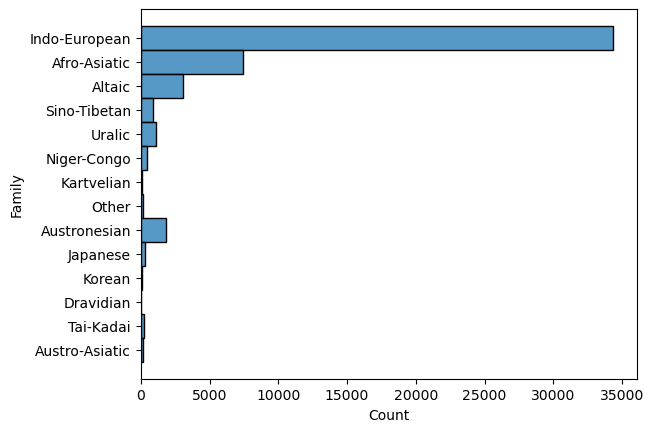

In [33]:
sns.histplot(data = df, y = 'Family', bins = len(df['Family']))

In [19]:
# add a column with an incrementing value based on the alphabetical order of L1
df['L1_Order'] = df.groupby('L1').ngroup()
pg.linear_regression(df['L1_Order'], df['Speaking'])

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,522.900955,0.326101,1603.495262,0.000000e+00,0.007068,0.007049,522.261794,523.540116
1,L1_Order,-0.159928,0.008457,-18.909996,1.784077e-79,0.007068,0.007049,-0.176505,-0.143352


<Axes: xlabel='L1_Order', ylabel='Speaking'>

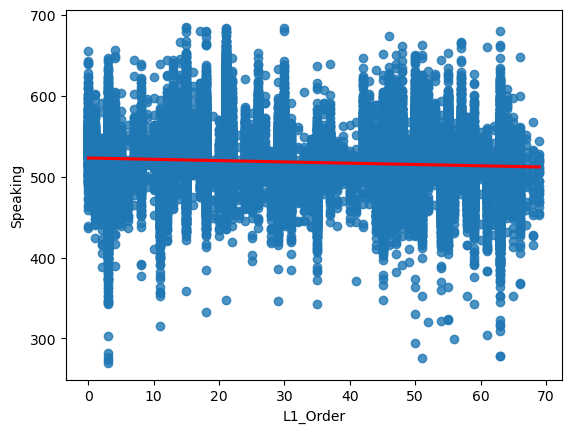

In [56]:
sns.regplot(data = df, x = 'L1_Order', y = 'Speaking', line_kws={"color": "red"})

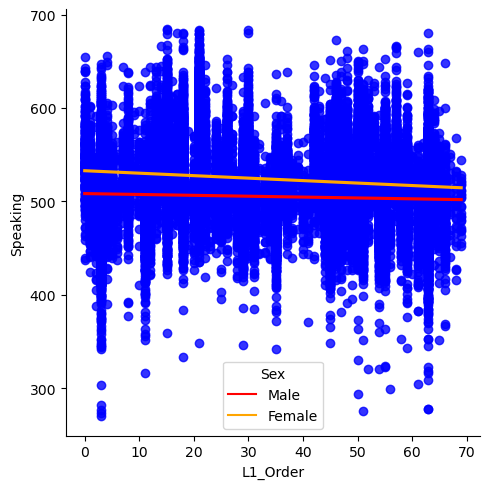

In [53]:
g = sns.lmplot(
    data=df,
    x='L1_Order',
    y='Speaking',
    hue='Sex',
    palette={'Male': 'red', 'Female': 'orange'},
    scatter_kws={'color': 'blue'},
    legend=False
)

g.ax.legend(
    handles=[
        Line2D([0], [0], color='red', label='Male'),
        Line2D([0], [0], color='orange', label='Female')
    ],
    title='Sex'
)


In [45]:
df['Sex_numeric'] = df['Sex'].map({'Male': 0, 'Female': 1})
pg.linear_regression(df[['L1_Order', 'Sex_numeric']], df['Speaking'])

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,511.434685,0.380052,1345.698235,0.000000e+00,0.062747,0.06271,510.689780,512.179591
1,L1_Order,-0.193900,0.008240,-23.530550,9.081447e-122,0.062747,0.06271,-0.210052,-0.177749
2,Sex_numeric,18.983400,0.347510,54.626916,0.000000e+00,0.062747,0.06271,18.302276,19.664524


<Axes: xlabel='morph', ylabel='Speaking'>

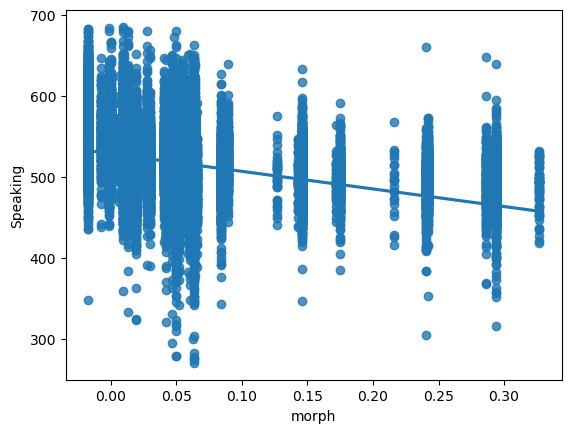

In [60]:
sns.regplot(x='morph', y='Speaking', data=df)